# Lab 05 – Intensity Transformations for Retinal Image Enhancement
**Course:** Digital Image Processing (Fall 2026)
**Name:** Hashir  **Reg No:** B23F0435AI108
**Instructor:** Mr. Assad Ali  **Lab Engineer:** Mr. Khizar Hayat

**Scenario:** retinal photographs arrive dark, washed out or hazy. This notebook builds a small enhancement toolkit (identity, negative, log, gamma, contrast stretching, intensity-level slicing), applies it to the four provided images and compares the results.

## 0. Setup
Upload `images.zip` (or the four PNGs) when prompted. The cell skips the upload if the images are already present.

In [1]:
import os, zipfile, glob
if not os.path.exists('images/retina_original.png'):
    try:
        from google.colab import files
        up = files.upload()
        os.makedirs('images', exist_ok=True)
        for name in up:
            if name.endswith('.zip'):
                zipfile.ZipFile(name).extractall('.')
            else:
                os.replace(name, os.path.join('images', name))
    except ImportError:
        pass
print(sorted(glob.glob('images/*.png')))

['images/retina_dark.png', 'images/retina_hazy.png', 'images/retina_original.png', 'images/retina_overexposed.png']


Image size: (512, 512) | FOV pixels: 200891


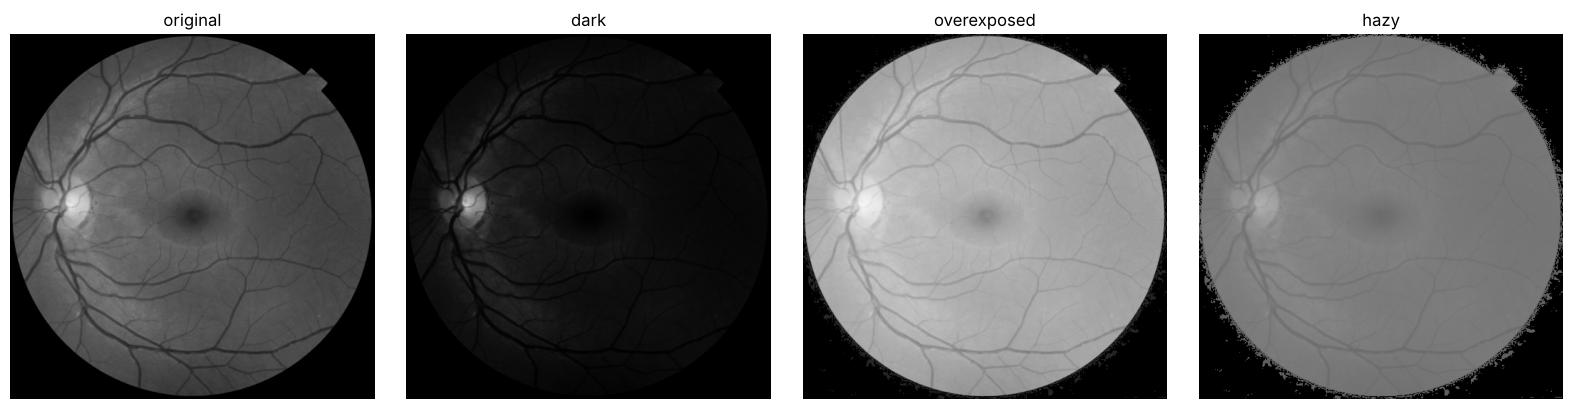

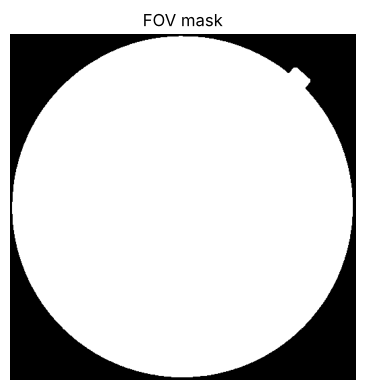

original               min= 16 max=234 mean=  82.9 std= 19.3
dark                   min=  0 max=205 mean=  16.5 std= 13.1
overexposed            min= 96 max=247 mean= 170.6 std= 13.3
hazy                   min=100 max=176 mean= 123.5 std=  6.8


In [2]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def load(name):
    return cv2.imread(f'images/{name}.png', cv2.IMREAD_GRAYSCALE)

orig = load('retina_original'); dark = load('retina_dark')
over = load('retina_overexposed'); hazy = load('retina_hazy')

# Field-of-view mask: the circular retina region (background outside it is black)
fov = cv2.morphologyEx((orig > 15).astype(np.uint8), cv2.MORPH_OPEN, np.ones((5,5), np.uint8)).astype(bool)
print('Image size:', orig.shape, '| FOV pixels:', fov.sum())

def show(imgs, titles, cmap='gray', size=4):
    fig, ax = plt.subplots(1, len(imgs), figsize=(size*len(imgs), size))
    for a, im, t in zip(np.atleast_1d(ax), imgs, titles):
        a.imshow(im, cmap=cmap, vmin=0, vmax=255); a.set_title(t); a.axis('off')
    plt.tight_layout(); plt.show()

def hist(imgs, titles, mask=None):
    fig, ax = plt.subplots(1, len(imgs), figsize=(4.5*len(imgs), 3))
    for a, im, t in zip(np.atleast_1d(ax), imgs, titles):
        v = im[mask] if mask is not None else im.ravel()
        a.hist(v, bins=256, range=(0, 255), color='steelblue'); a.set_title(t); a.set_xlim(0, 255)
    plt.tight_layout(); plt.show()

def psnr(a, b, mask=fov):
    mse = np.mean((a[mask].astype(float) - b[mask].astype(float))**2)
    return float('inf') if mse == 0 else 10*np.log10(255**2/mse)

def stats(name, im):
    v = im[fov]
    print(f'{name:22s} min={v.min():3d} max={v.max():3d} mean={v.mean():6.1f} std={v.std():5.1f}')

show([orig, dark, over, hazy], ['original', 'dark', 'overexposed', 'hazy'])
show([fov.astype(np.uint8)*255], ['FOV mask'])
for n, im in [('original', orig), ('dark', dark), ('overexposed', over), ('hazy', hazy)]:
    stats(n, im)

## Task 1 – Identity transformation  s = r

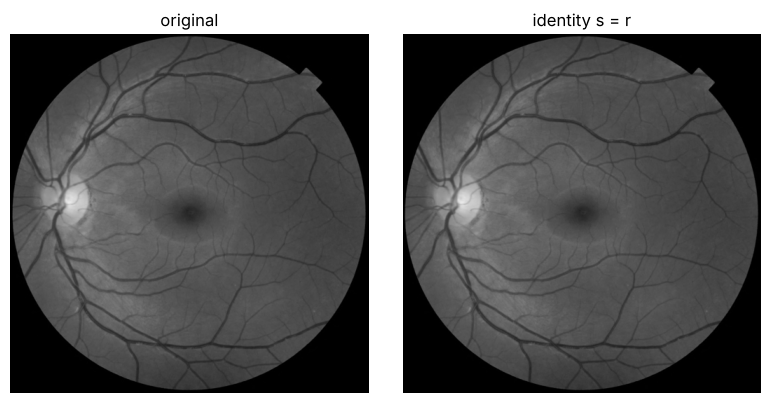

Identical to input: True | PSNR: inf


In [3]:
def identity(r):
    return r.copy()

ident = identity(orig)
show([orig, ident], ['original', 'identity s = r'])
print('Identical to input:', np.array_equal(ident, orig), '| PSNR:', psnr(ident, orig))

The identity map leaves every grey level unchanged, so the output equals the input pixel for pixel (PSNR is infinite). It serves as the baseline for the other transforms.

## Task 2 – Image negative  s = 255 − r

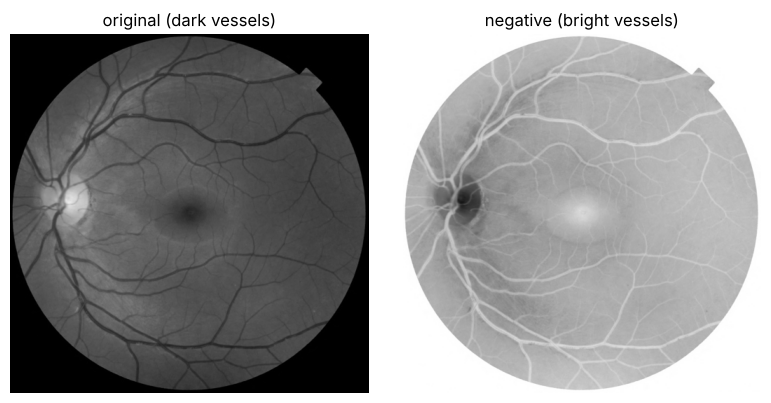

Original : vessel mean = 65.6, retina mean = 82.9
Negative : vessel mean = 189.4, retina mean = 172.1


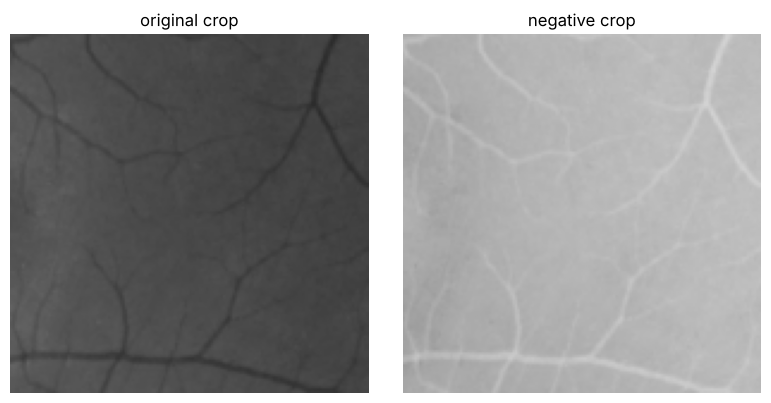

negative(negative(img)) == original: True


In [4]:
def negative(r):
    return (255 - r.astype(np.int16)).astype(np.uint8)

neg = negative(orig)
show([orig, neg], ['original (dark vessels)', 'negative (bright vessels)'])

# Check that vessels go from darker-than-background to brighter-than-background
bg = cv2.medianBlur(orig, 21)                       # local retina background
vessels = fov & (orig.astype(int) < bg.astype(int) - 12)
print(f'Original : vessel mean = {orig[vessels].mean():.1f}, retina mean = {orig[fov].mean():.1f}')
print(f'Negative : vessel mean = {neg[vessels].mean():.1f}, retina mean = {neg[fov].mean():.1f}')

# Zoomed crop to see the vessels clearly
y, x = 180, 300
show([orig[y:y+150, x:x+150], neg[y:y+150, x:x+150]], ['original crop', 'negative crop'])

twice = negative(negative(orig))
print('negative(negative(img)) == original:', np.array_equal(twice, orig))

In the original the vessels are darker than the surrounding retina. After the negative they are the brightest structures within the retina, which is the bright-vessel format the tracing software wants. One side effect: the black area outside the field of view turns white, so in practice the FOV mask should be applied afterwards (multiply by the mask) so the background stays dark.

Applying the negative twice gives 255 − (255 − r) = r, and the check above confirms the result is identical to the original.

## Task 3 – Log transformation  s = c·log(1 + r)  on retina_dark

c = 47.84


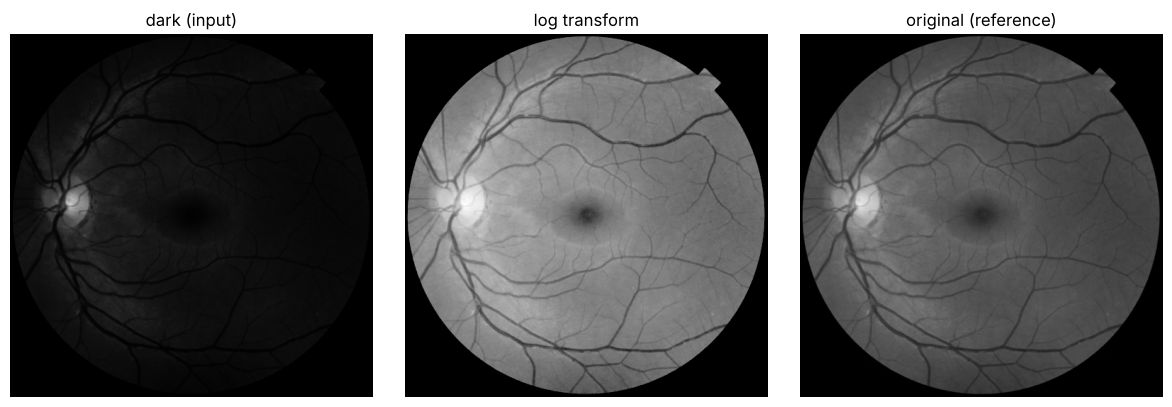

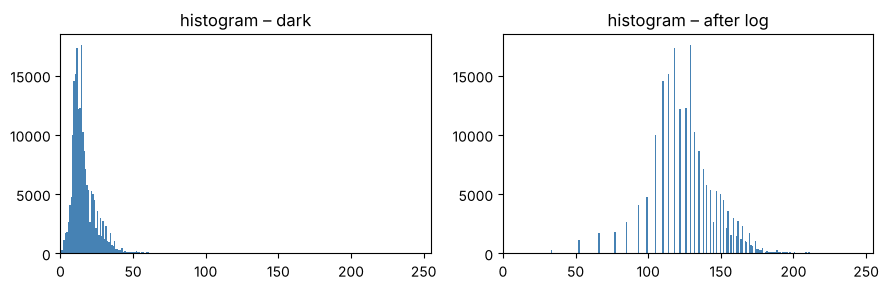

dark                   min=  0 max=205 mean=  16.5 std= 13.1
log(dark)              min=  0 max=254 mean= 129.1 std= 25.1
PSNR vs original (FOV): dark = 11.62 dB, log = 14.71 dB


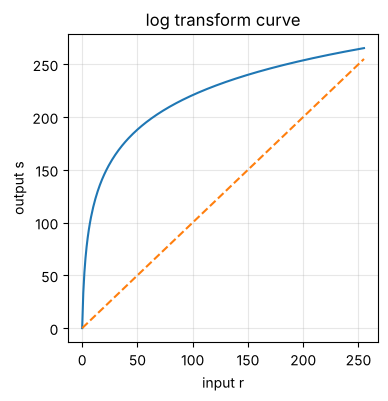

In [5]:
def log_transform(r):
    c = 255 / np.log(1 + r.max())          # maps the brightest input to 255
    return np.clip(c * np.log1p(r.astype(float)), 0, 255).astype(np.uint8), c

log_dark, c = log_transform(dark)
print(f'c = {c:.2f}')
show([dark, log_dark, orig], ['dark (input)', 'log transform', 'original (reference)'])
hist([dark, log_dark], ['histogram – dark', 'histogram – after log'], mask=fov)
stats('dark', dark); stats('log(dark)', log_dark)
print(f'PSNR vs original (FOV): dark = {psnr(dark, orig):.2f} dB, log = {psnr(log_dark, orig):.2f} dB')

r = np.arange(256)
plt.figure(figsize=(4,4)); plt.plot(r, c*np.log1p(r)); plt.plot(r, r, '--')
plt.title('log transform curve'); plt.xlabel('input r'); plt.ylabel('output s'); plt.grid(alpha=.3); plt.show()

**Why the log transform helps:** in the dark image almost all retina pixels are packed into the bottom few grey levels, so the histogram is a narrow spike near 0. The log curve is very steep for small r and flat for large r. It spreads those few low levels across a much wider output range and compresses the few bright values (the optic disc), so hidden detail in the shadows becomes visible. After the transform the histogram moves right and gets wider.

The drawback is that c·log(1+r) has a fixed shape. It tends to overshoot the mid-tones and make the image look flat and greyish, which is why the PSNR against the reference only improves modestly. Gamma correction (Task 4) offers a tunable curve.

## Task 4 – Power-law (gamma) transformation  s = 255·(r/255)^γ

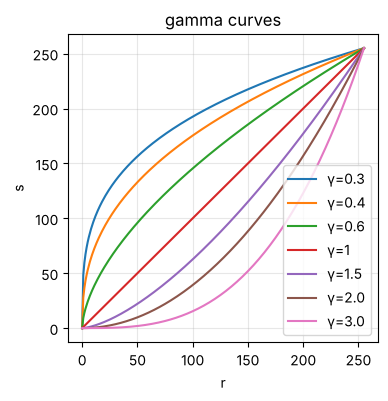

In [6]:
def gamma_transform(r, g):
    return np.clip(255 * (r.astype(float) / 255) ** g, 0, 255).astype(np.uint8)

r = np.arange(256)
plt.figure(figsize=(4,4))
for g in [0.3, 0.4, 0.6, 1, 1.5, 2.0, 3.0]:
    plt.plot(r, 255*(r/255)**g, label=f'γ={g}')
plt.legend(); plt.grid(alpha=.3); plt.title('gamma curves'); plt.xlabel('r'); plt.ylabel('s'); plt.show()

### 4a. Brightening retina_dark with γ = 0.3, 0.4, 0.6

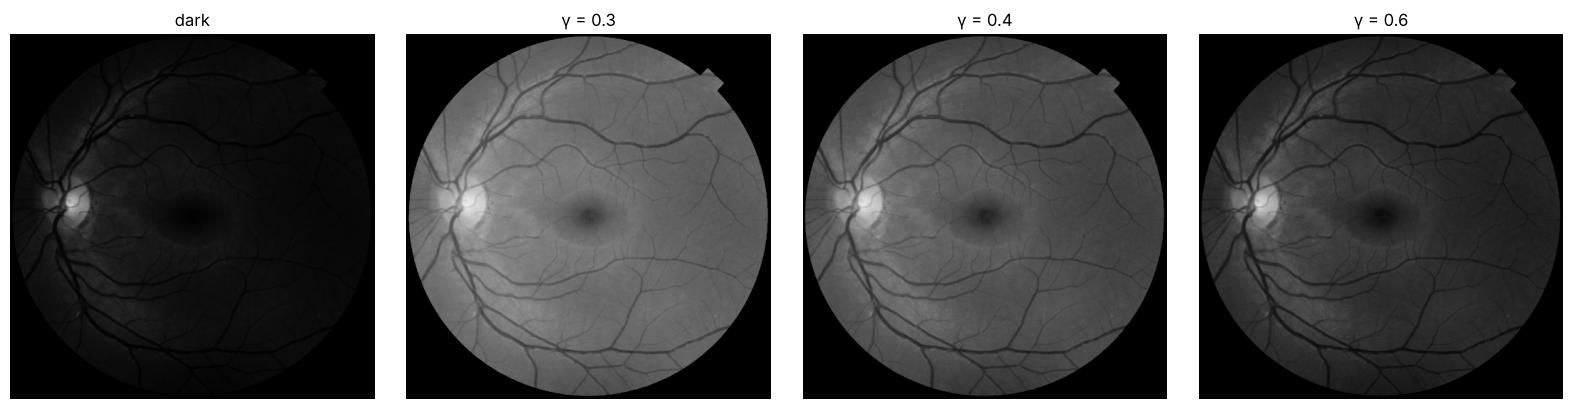

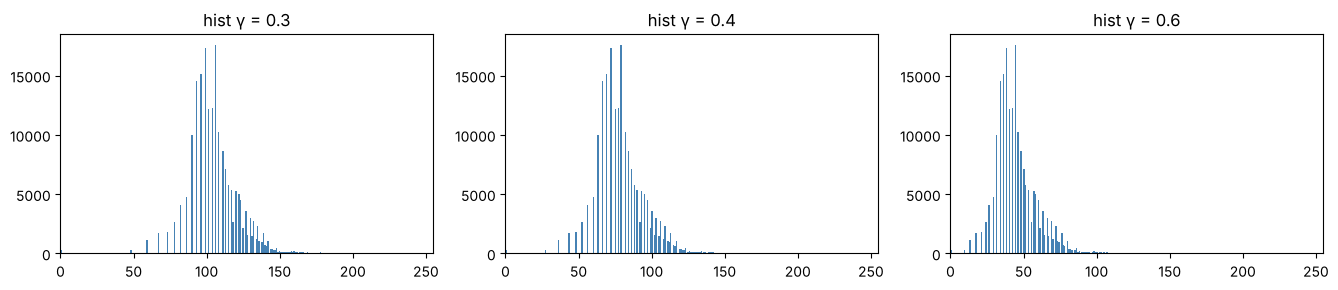

dark γ=0.3             min=  0 max=238 mean= 107.5 std= 19.3
dark γ=0.4             min=  0 max=233 mean=  81.1 std= 19.8
dark γ=0.6             min=  0 max=223 mean=  46.6 std= 18.2


In [7]:
dark_gammas = [0.3, 0.4, 0.6]
dark_out = {g: gamma_transform(dark, g) for g in dark_gammas}
show([dark] + [dark_out[g] for g in dark_gammas], ['dark'] + [f'γ = {g}' for g in dark_gammas])
hist([dark_out[g] for g in dark_gammas], [f'hist γ = {g}' for g in dark_gammas], mask=fov)
for g in dark_gammas:
    stats(f'dark γ={g}', dark_out[g])

### 4b. Fixing retina_overexposed with γ > 1

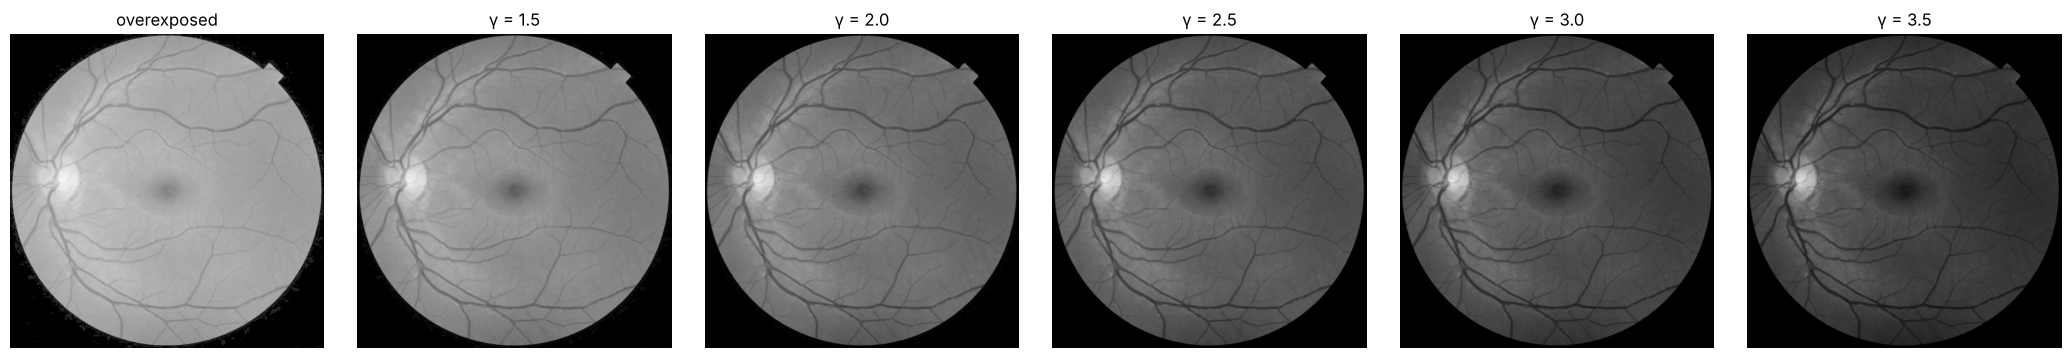

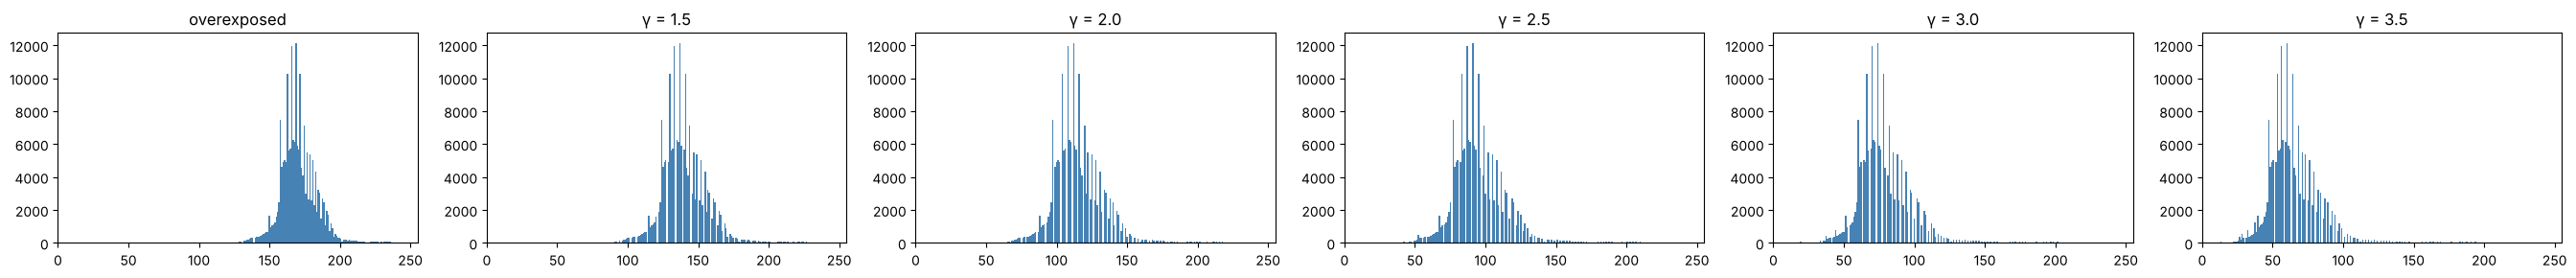

In [8]:
over_gammas = [1.5, 2.0, 2.5, 3.0, 3.5]
over_out = {g: gamma_transform(over, g) for g in over_gammas}
show([over] + [over_out[g] for g in over_gammas], ['overexposed'] + [f'γ = {g}' for g in over_gammas], size=3.5)
hist([over] + [over_out[g] for g in over_gammas], ['overexposed'] + [f'γ = {g}' for g in over_gammas], mask=fov)

### 4c. Choosing γ by PSNR (field of view only)

,image,gamma,PSNR (dB)
0,dark,none (input),11.62
1,dark,0.3,20.26
2,dark,0.4,41.56
3,dark,0.6,16.93
4,overexposed,none (input),9.24
5,overexposed,1.5,13.07
6,overexposed,2.0,18.13
7,overexposed,2.5,27.18
8,overexposed,3.0,33.16
9,overexposed,3.5,22.41


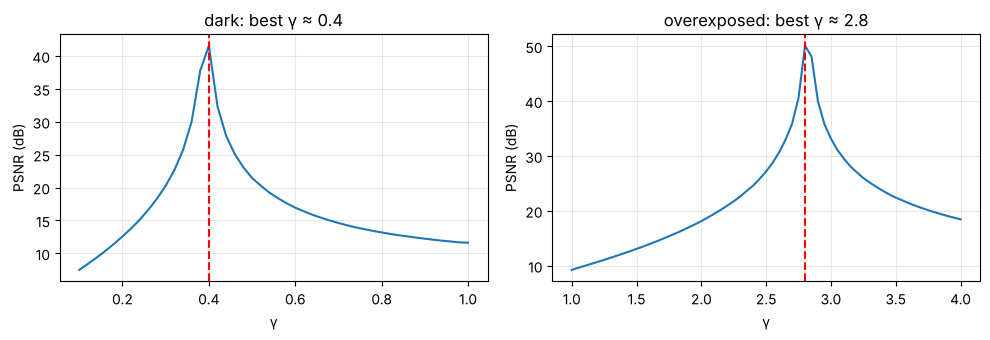

Best tested γ for dark: 0.4  (41.56 dB)
Best tested γ for overexposed: 3.0  (33.16 dB)


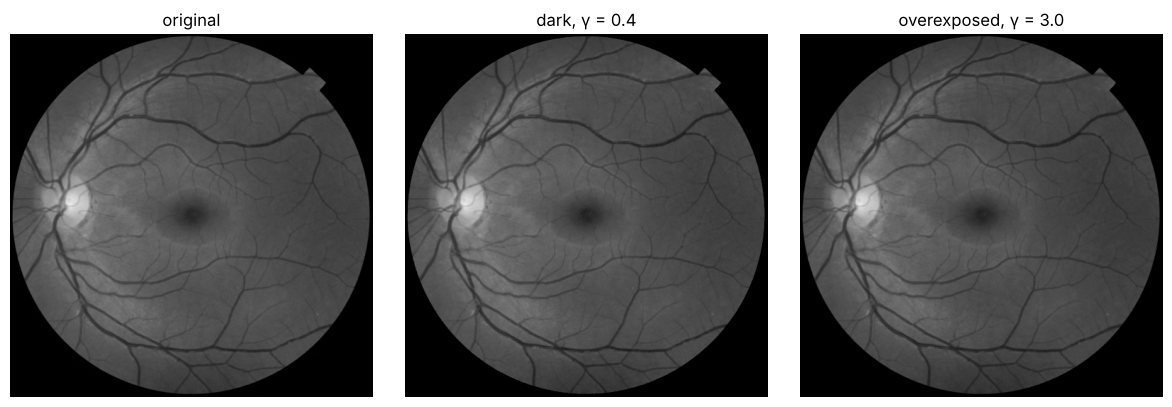

In [9]:
import pandas as pd
rows = [('dark', 'none (input)', psnr(dark, orig))]
rows += [('dark', g, psnr(dark_out[g], orig)) for g in dark_gammas]
rows += [('overexposed', 'none (input)', psnr(over, orig))]
rows += [('overexposed', g, psnr(over_out[g], orig)) for g in over_gammas]
df = pd.DataFrame(rows, columns=['image', 'gamma', 'PSNR (dB)']).round(2)
display(df)

# Fine sweep to see where the optimum really is
sweep_d = np.round(np.arange(0.1, 1.01, 0.02), 2)
sweep_o = np.round(np.arange(1.0, 4.01, 0.05), 2)
pd_ = [psnr(gamma_transform(dark, g), orig) for g in sweep_d]
po_ = [psnr(gamma_transform(over, g), orig) for g in sweep_o]
best_d = sweep_d[int(np.argmax(pd_))]; best_o = sweep_o[int(np.argmax(po_))]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(sweep_d, pd_); ax[0].axvline(best_d, ls='--', c='r'); ax[0].set_title(f'dark: best γ ≈ {best_d}')
ax[1].plot(sweep_o, po_); ax[1].axvline(best_o, ls='--', c='r'); ax[1].set_title(f'overexposed: best γ ≈ {best_o}')
for a in ax: a.set_xlabel('γ'); a.set_ylabel('PSNR (dB)'); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

bd = max(dark_gammas, key=lambda g: psnr(dark_out[g], orig))
bo = max(over_gammas, key=lambda g: psnr(over_out[g], orig))
print(f'Best tested γ for dark: {bd}  ({psnr(dark_out[bd], orig):.2f} dB)')
print(f'Best tested γ for overexposed: {bo}  ({psnr(over_out[bo], orig):.2f} dB)')
show([orig, dark_out[bd], over_out[bo]], ['original', f'dark, γ = {bd}', f'overexposed, γ = {bo}'])

**Discussion.**

*Dark image:* γ = 0.3 over-brightens (mean ≈ 108 vs 83 in the reference) and flattens the image, while γ = 0.6 is not strong enough (mean ≈ 47, still too dark). γ = 0.4 gives a mean of ≈ 81 and a spread almost identical to the reference, and its PSNR (≈ 41.6 dB) is about 20 dB higher than the other two values.

*Overexposed image:* PSNR rises steadily from γ = 1.5 to γ = 3.0 (≈ 33.2 dB) and then falls again at 3.5, where the image becomes too dark. γ = 3.0 is the best value.

**Why one γ is clearly better:** a gamma curve is inverted by the reciprocal exponent, since (r^a)^(1/a) = r. The sharp peak in the PSNR sweeps shows the dark image behaves like the original passed through a power law with exponent about 2.5 (1/0.4), and the overexposed one like a power law with exponent about 1/3. Choosing the γ that undoes that curve restores nearly the original grey levels. Every other γ leaves a systematic brightness error over the whole retina, which shows up as a large MSE. The small leftover error comes from 8-bit rounding: the dark image squeezed many levels into a handful of values, and those cannot be fully recovered.

## Task 5 – Contrast stretching (global min / max) on retina_hazy

Whole image : rmin = 0, rmax = 176
FOV only    : rmin = 100, rmax = 176


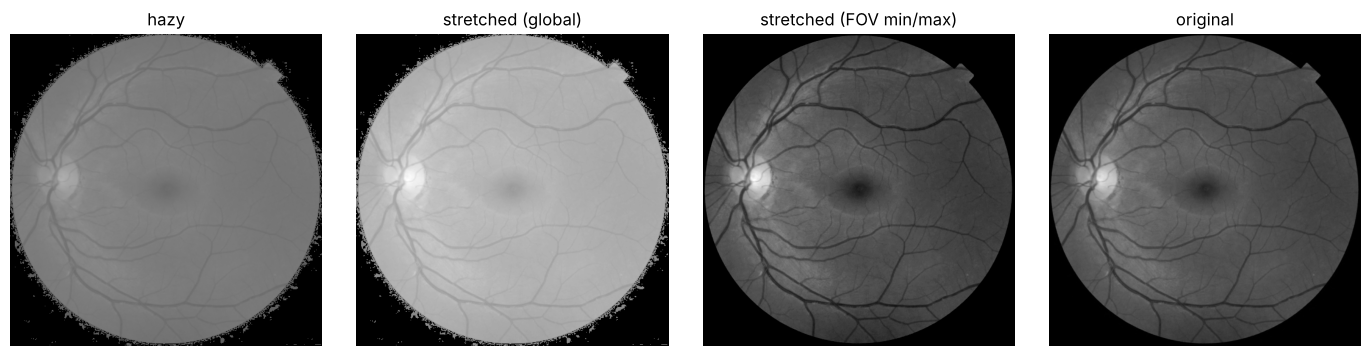

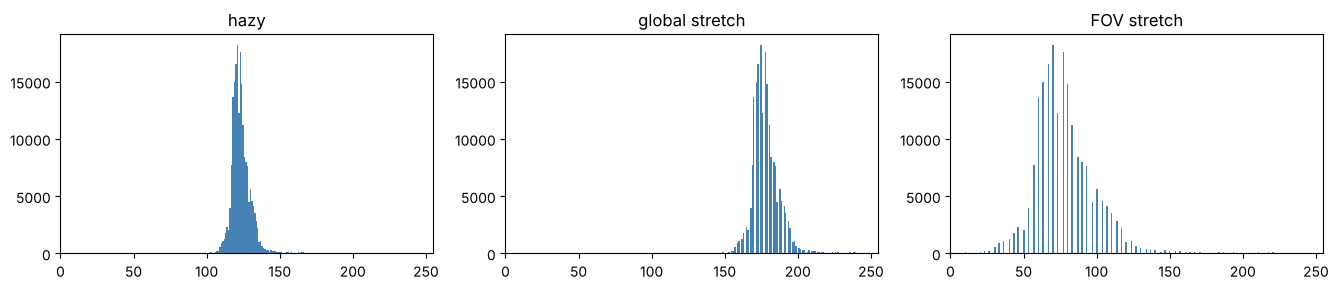

hazy                   min=100 max=176 mean= 123.5 std=  6.8
                       PSNR vs original = 15.55 dB
global stretch         min=144 max=255 mean= 178.5 std=  9.8
                       PSNR vs original = 8.48 dB
FOV stretch            min=  0 max=255 mean=  78.4 std= 22.7
                       PSNR vs original = 33.12 dB


In [10]:
def contrast_stretch(r, mask=None):
    v = r[mask] if mask is not None else r
    rmin, rmax = int(v.min()), int(v.max())
    s = (r.astype(float) - rmin) * 255 / (rmax - rmin)
    return np.clip(s, 0, 255).astype(np.uint8), rmin, rmax

hz_all, mn_a, mx_a = contrast_stretch(hazy)          # whole image
hz_fov, mn_f, mx_f = contrast_stretch(hazy, fov)     # retina only
hz_fov = np.where(fov, hz_fov, 0).astype(np.uint8)
print(f'Whole image : rmin = {mn_a}, rmax = {mx_a}')
print(f'FOV only    : rmin = {mn_f}, rmax = {mx_f}')
show([hazy, hz_all, hz_fov, orig], ['hazy', 'stretched (global)', 'stretched (FOV min/max)', 'original'], size=3.5)
hist([hazy, hz_all, hz_fov], ['hazy', 'global stretch', 'FOV stretch'], mask=fov)
for n, im in [('hazy', hazy), ('global stretch', hz_all), ('FOV stretch', hz_fov)]:
    stats(n, im); print(f'{"":22s} PSNR vs original = {psnr(im, orig):.2f} dB')

**Discussion.** The hazy retina only uses grey levels 100–176 (std ≈ 6.8 compared with 19.3 in the reference), so it looks foggy.

An important detail: the black background outside the eye has value 0. A plain global min/max stretch on the whole image therefore uses rmin = 0 and only rescales by 255/176. The retina gets brighter but no more contrasty, and the PSNR actually drops (≈ 8.5 dB). Taking the min and max over the field of view only (100 and 176) maps that narrow band onto the full 0–255 range. Contrast roughly triples (std ≈ 22.7), the vessels become sharp again and the PSNR reaches ≈ 33 dB.

Limitation: the stretch is linear and driven by two single pixels. One bright reflection or one noisy pixel can set rmax and ruin the result, so a percentile-based stretch (e.g. 1st–99th percentile) is more robust.

## Task 6 – Intensity-level slicing

Percentiles of retina grey levels (FOV):
      1% -> 44
      5% -> 59
     10% -> 65
     25% -> 71
     50% -> 80
     75% -> 92
     95% -> 114
     99% -> 151
   99.5% -> 180
   99.9% -> 209


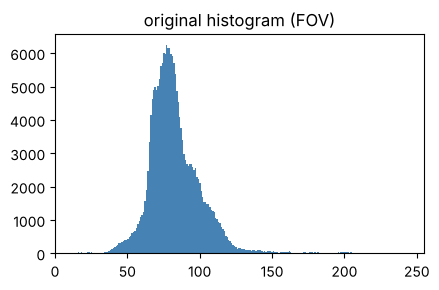

In [11]:
def slice_keep(r, A, B):
    out = r.copy(); out[(r >= A) & (r <= B)] = 255; return out

def slice_binary(r, A, B):
    return np.where((r >= A) & (r <= B), 255, 0).astype(np.uint8)

v = orig[fov]
print('Percentiles of retina grey levels (FOV):')
for p in [1, 5, 10, 25, 50, 75, 95, 99, 99.5, 99.9]:
    print(f'  {p:5}% -> {np.percentile(v, p):.0f}')
hist([orig], ['original histogram (FOV)'], mask=fov)

Blood vessels: range [30, 60] -> 11722 pixels selected (11717 inside FOV, 5.8% of retina)


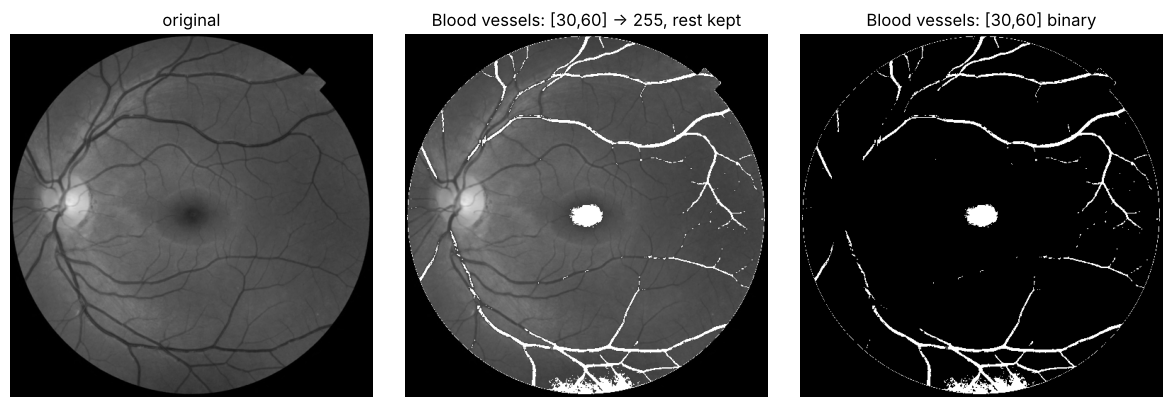

Optic disc: range [185, 255] -> 861 pixels selected (861 inside FOV, 0.4% of retina)


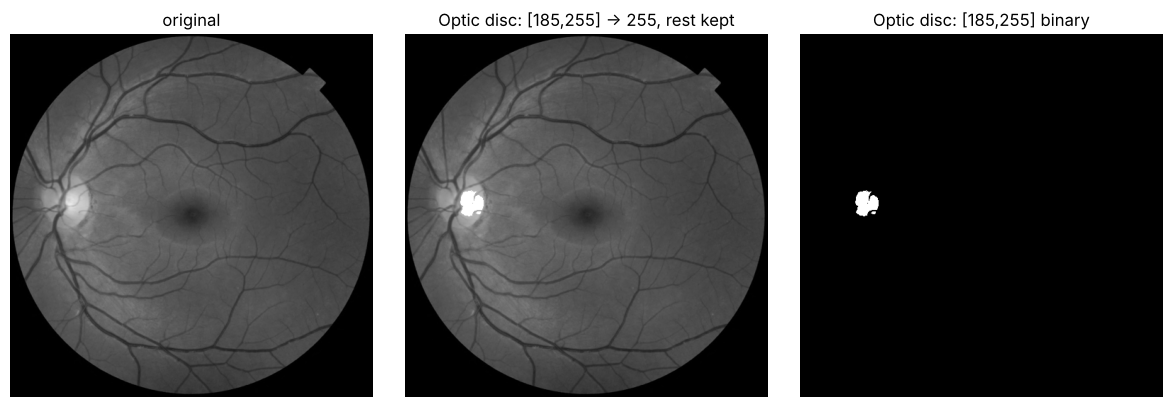

In [12]:
VA, VB = 30, 60      # blood vessels (dark structures inside the retina)
DA, DB = 185, 255      # optic disc (brightest region)

for name, (A, B) in [('Blood vessels', (VA, VB)), ('Optic disc', (DA, DB))]:
    sel = (orig >= A) & (orig <= B)
    n_all, n_fov = int(sel.sum()), int((sel & fov).sum())
    print(f'{name}: range [{A}, {B}] -> {n_all} pixels selected ({n_fov} inside FOV, {100*n_fov/fov.sum():.1f}% of retina)')
    show([orig, slice_keep(orig, A, B), slice_binary(orig, A, B)],
         ['original', f'{name}: [{A},{B}] -> 255, rest kept', f'{name}: [{A},{B}] binary'])

**Ranges chosen and pixels selected**

| Target | Range [A, B] | Pixels selected | Share of retina |
|---|---|---|---|
| Blood vessels | [30, 60] | 11,722 | ≈ 5.8 % |
| Optic disc | [185, 255] | 861 | ≈ 0.4 % |

The vessel range sits below the 5th percentile of the retina (59) and covers most of the vessel pixels (median vessel grey level ≈ 62). The disc range sits above the 99.5th percentile (180).

**Unintended highlights**

- *Vessel range:* the **macula/fovea** in the centre is just as dark as the vessels, so it shows up as a solid blob. A thin **ring along the edge of the field of view** is also selected, because the retina darkens towards its border (vignetting), and so is a darker **patch at the bottom** of the image. The thinnest capillaries are lighter than 60, so they are missed, and the wide vessels near the disc are brighter than average, so some of them break up.
- *Disc range:* only the brightest core of the optic disc passes; its outer rim overlaps normal retina values. Bright **light reflexes on the large vessels** next to the disc can also fall into the range. Lowering A to pick up the full disc quickly brings in bright background patches.

Slicing works on grey level alone, without any notion of shape or position, so any structure with the same brightness is highlighted as well.

## Task 7 – Comparative analysis

,Transform,Image,Problem,PSNR before → after (dB)
0,Identity,original,—,inf
1,Negative,original,vessel tracing,n/a
2,Log,dark,under-exposure,11.62 → 14.71
3,Gamma γ=0.4,dark,under-exposure,11.62 → 41.56
4,Gamma γ=3.0,overexposed,washed out,9.24 → 33.16
5,Contrast stretch,hazy,low contrast,15.55 → 33.12


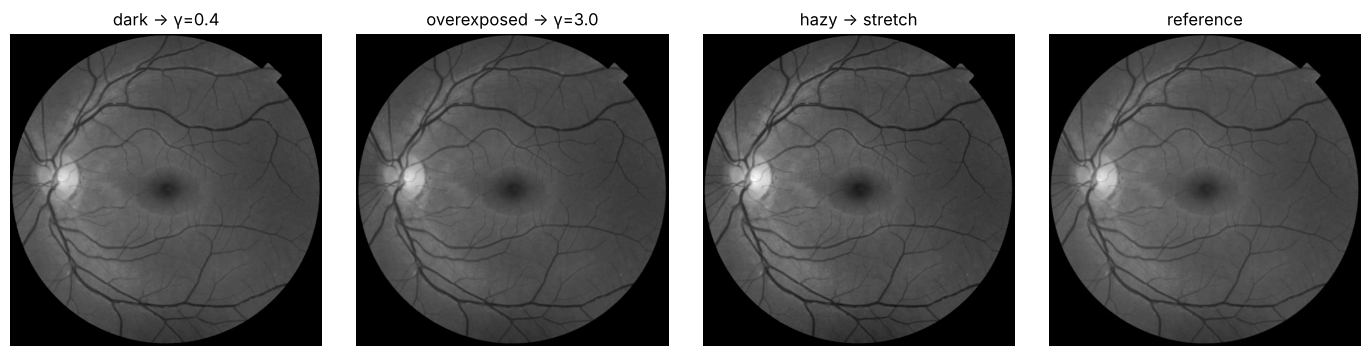

In [13]:
summary = pd.DataFrame([
    ['Identity', 'original', '—', 'inf'],
    ['Negative', 'original', 'vessel tracing', 'n/a'],
    ['Log', 'dark', 'under-exposure', f'{psnr(dark, orig):.2f} → {psnr(log_dark, orig):.2f}'],
    [f'Gamma γ={bd}', 'dark', 'under-exposure', f'{psnr(dark, orig):.2f} → {psnr(dark_out[bd], orig):.2f}'],
    [f'Gamma γ={bo}', 'overexposed', 'washed out', f'{psnr(over, orig):.2f} → {psnr(over_out[bo], orig):.2f}'],
    ['Contrast stretch', 'hazy', 'low contrast', f'{psnr(hazy, orig):.2f} → {psnr(hz_fov, orig):.2f}'],
], columns=['Transform', 'Image', 'Problem', 'PSNR before → after (dB)'])
display(summary)
show([dark_out[bd], over_out[bo], hz_fov, orig], [f'dark → γ={bd}', f'overexposed → γ={bo}', 'hazy → stretch', 'reference'], size=3.5)

### Comparison table

| Transformation | Problem it addresses | Observed effect on our images | One limitation |
|---|---|---|---|
| Identity s = r | None, used as a baseline/reference | Output identical to input (PSNR = ∞) | Does not enhance anything |
| Negative s = 255 − r | Makes dark detail on a dark/mid background easier to see; gives bright vessels for the tracing software | Vessels go from mean ≈ 66 (darker than retina) to ≈ 189 (brighter than retina); applying it twice returns the original exactly | Background outside the FOV turns white; must be masked. Adds no new contrast |
| Log s = c·log(1+r) | Under-exposed images with detail hidden in low grey levels | Mean of dark image 16.5 → 129, histogram spread to the right, PSNR 11.6 → 14.7 dB | Fixed curve shape: overshoots mid-tones and looks flat/grey; cannot be tuned |
| Power law s = 255(r/255)^γ | γ < 1 for dark images, γ > 1 for washed-out ones | Dark: γ = 0.4 → 41.6 dB; overexposed: γ = 3.0 → 33.2 dB; both look very close to the reference | Needs the right γ; wrong values clearly over- or under-correct; quantisation loss in very dark images cannot be undone |
| Contrast stretching | Low-contrast / hazy images using a narrow grey range | FOV stretch maps 100–176 to 0–255, std 6.8 → 22.7, PSNR 15.6 → 33.1 dB | Sensitive to outliers and to the black background (global min = 0 makes it ineffective) |
| Intensity-level slicing | Isolating structures in a known grey range (vessels, optic disc) | [30, 60] marks 11,722 vessel pixels; [185, 255] marks 861 optic-disc pixels | Picks up anything in the same range (fovea, FOV edge, light reflexes); thresholds are image-specific |

### Conclusion

- **Dark images:** power-law with **γ ≈ 0.4** is the best option, with by far the highest PSNR. The log transform helps but is not adjustable.
- **Washed-out images:** power-law with **γ ≈ 3.0**.
- **Hazy images:** **contrast stretching on the field-of-view pixels only.** Using the whole image's min/max does not work because of the black background.
- For the screening pipeline, the most useful combination is: **correct exposure first (gamma or FOV contrast stretch, depending on the problem) → negative (masked to the FOV) → intensity slicing.** That gives the vessel-tracing software bright vessels on a dark background with consistent grey levels, so a single fixed slicing range works for every patient image.